# 04 — XAUUSD H1 Swing-Window Sensitivity Experiment

## Research objective

This notebook tests how changing the **confirmed swing-pivot width** affects the existing N-Method implementation when trades are selected using the EMA/ADX baseline regimes.

Four symmetric pivot definitions are compared:

- **2-bar swing:** 2 bars to the left and 2 bars to the right of the pivot (5-bar pivot window).
- **3-bar swing:** 3 bars to the left and 3 bars to the right (7-bar pivot window; current baseline).
- **4-bar swing:** 4 bars to the left and 4 bars to the right (9-bar pivot window).
- **5-bar swing:** 5 bars to the left and 5 bars to the right (11-bar pivot window).

The experiment applies the selected H1 trading framework:

1. **Bullish N only when the signal candle is classified as Bullish by EMA/ADX.**
2. **Ranging N only when the signal candle is classified as Sideways by EMA/ADX.**
3. Bearish N is not included in the selected trading configuration.

The main output compares the Bullish N component, the Ranging N component, and their combined trade-level results for each swing width.

> **Research status:** this is a full-history exploratory sensitivity experiment. Since four swing widths are inspected and compared, the best historical result must not be treated as an unbiased estimate of future performance. A selected width must be frozen and evaluated on a new untouched period or through walk-forward validation.

## Important interpretation of “2/3/4/5-bar swing”

In this notebook, the number means the number of candles **on each side** of the candidate pivot. A 3-bar swing therefore requires three completed candles to the left and three completed candles to the right. The pivot becomes usable only after the right-side confirmation candles have closed. This is the same convention used in the existing 3-bar H1 N-Method baseline.

In [1]:
from __future__ import annotations

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from numpy.lib.stride_tricks import sliding_window_view

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA_PATH = PROJECT_ROOT / "data" / "XAUUSD_H1.csv"
REFERENCE_TRADES_PATH = PROJECT_ROOT / "outputs" / "XAUUSD_H1_N_method_trades.csv"
OUTPUT_DIR = PROJECT_ROOT / "outputs"
ASSET_DIR = PROJECT_ROOT / "assets"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
ASSET_DIR.mkdir(parents=True, exist_ok=True)

if not DATA_PATH.exists():
    raise FileNotFoundError(
        f"Could not find {DATA_PATH}. Run this notebook from the project root or notebooks/ folder."
    )

print("Project root:", PROJECT_ROOT)
print("Source data:", DATA_PATH)

Project root: /Users/febrianamisdianti/Documents/XAUUSD_regime_analysis_on_n_pattern
Source data: /Users/febrianamisdianti/Documents/XAUUSD_regime_analysis_on_n_pattern/data/XAUUSD_H1.csv


In [2]:
# Keep all non-swing parameters identical to the existing H1 N-Method baseline.
SWING_WIDTHS = [2, 3, 4, 5]  # bars on EACH side of the pivot
ATR_PERIOD = 14
RR = 2.0
ENTRY_BUFFER_ATR = 0.05
SL_BUFFER_ATR = 0.05
RANGE_TOLERANCE_ATR = 0.50
EXPIRY_BARS = 20
ONE_POSITION_AT_A_TIME = True

EMA_FAST = 50
EMA_SLOW = 200
ADX_PERIOD = 14
ADX_THRESHOLD = 20.0

SELECTED_SETUPS = {
    "Bullish N + EMA/ADX Bullish": ("bullish", "Bullish"),
    "Ranging N + EMA/ADX Sideways": ("ranging", "Sideways"),
}

print({
    "swing_widths_bars_each_side": SWING_WIDTHS,
    "pivot_total_window_sizes": {w: 2 * w + 1 for w in SWING_WIDTHS},
    "ATR_period": ATR_PERIOD,
    "risk_reward": f"1:{RR:g}",
    "entry_buffer_ATR": ENTRY_BUFFER_ATR,
    "stop_buffer_ATR": SL_BUFFER_ATR,
    "range_tolerance_ATR": RANGE_TOLERANCE_ATR,
    "pending_order_expiry_H1_bars": EXPIRY_BARS,
    "EMA_periods": [EMA_FAST, EMA_SLOW],
    "ADX_period_threshold": [ADX_PERIOD, ADX_THRESHOLD],
})

{'swing_widths_bars_each_side': [2, 3, 4, 5], 'pivot_total_window_sizes': {2: 5, 3: 7, 4: 9, 5: 11}, 'ATR_period': 14, 'risk_reward': '1:2', 'entry_buffer_ATR': 0.05, 'stop_buffer_ATR': 0.05, 'range_tolerance_ATR': 0.5, 'pending_order_expiry_H1_bars': 20, 'EMA_periods': [50, 200], 'ADX_period_threshold': [14, 20.0]}


## 1. Load H1 data and calculate ATR / EMA-ADX regimes

The H1 file is interpreted as headerless `Date, Open, High, Low, Close, Volume` data. Regime assignment is performed at the **setup signal/confirmation timestamp**, not at the later entry or exit timestamp.

The EMA/ADX rules exactly match Notebook 02:

- Bullish: ADX(14) ≥ 20 and EMA(50) > EMA(200)
- Bearish: ADX(14) ≥ 20 and EMA(50) < EMA(200)
- Sideways: ADX(14) < 20
- Unclassified: required indicators are unavailable or EMA values are equal while ADX ≥ 20

In [3]:
raw = pd.read_csv(DATA_PATH, header=None)
if raw.shape[1] < 5:
    raise ValueError("The H1 source CSV must contain at least Date, Open, High, Low, and Close.")

column_names = ["Date", "Open", "High", "Low", "Close"]
if raw.shape[1] >= 6:
    column_names.append("Volume")
raw = raw.iloc[:, :len(column_names)].copy()
raw.columns = column_names
raw["Date"] = pd.to_datetime(raw["Date"], errors="coerce")
for col in ["Open", "High", "Low", "Close"]:
    raw[col] = pd.to_numeric(raw[col], errors="coerce")
if "Volume" in raw.columns:
    raw["Volume"] = pd.to_numeric(raw["Volume"], errors="coerce")

data = (
    raw.dropna(subset=["Date", "Open", "High", "Low", "Close"])
       .sort_values("Date")
       .drop_duplicates("Date")
       .set_index("Date")
)

invalid = (data["High"] < data[["Open", "Close", "Low"]].max(axis=1)) | (
    data["Low"] > data[["Open", "Close", "High"]].min(axis=1)
)
if invalid.any():
    raise ValueError(f"Found {invalid.sum()} invalid OHLC rows.")

# ATR uses the same simple rolling mean of True Range as Notebook 01.
prev_close = data["Close"].shift(1)
true_range = pd.concat([
    data["High"] - data["Low"],
    (data["High"] - prev_close).abs(),
    (data["Low"] - prev_close).abs(),
], axis=1).max(axis=1)
data["ATR"] = true_range.rolling(ATR_PERIOD, min_periods=ATR_PERIOD).mean()

# EMA(50), EMA(200), and Wilder-style ADX(14), matching Notebook 02.
data["EMA50"] = data["Close"].ewm(span=EMA_FAST, adjust=False, min_periods=EMA_FAST).mean()
data["EMA200"] = data["Close"].ewm(span=EMA_SLOW, adjust=False, min_periods=EMA_SLOW).mean()
up_move = data["High"].diff()
down_move = -data["Low"].diff()
plus_dm = pd.Series(np.where((up_move > down_move) & (up_move > 0), up_move, 0.0), index=data.index)
minus_dm = pd.Series(np.where((down_move > up_move) & (down_move > 0), down_move, 0.0), index=data.index)
smoothed_tr = true_range.ewm(alpha=1/ADX_PERIOD, adjust=False, min_periods=ADX_PERIOD).mean()
smoothed_plus_dm = plus_dm.ewm(alpha=1/ADX_PERIOD, adjust=False, min_periods=ADX_PERIOD).mean()
smoothed_minus_dm = minus_dm.ewm(alpha=1/ADX_PERIOD, adjust=False, min_periods=ADX_PERIOD).mean()
data["+DI14"] = 100 * smoothed_plus_dm / smoothed_tr
data["-DI14"] = 100 * smoothed_minus_dm / smoothed_tr
dx = 100 * (data["+DI14"] - data["-DI14"]).abs() / (data["+DI14"] + data["-DI14"])
data["ADX14"] = dx.ewm(alpha=1/ADX_PERIOD, adjust=False, min_periods=ADX_PERIOD).mean()

conditions = [
    data["ADX14"] < ADX_THRESHOLD,
    (data["ADX14"] >= ADX_THRESHOLD) & (data["EMA50"] > data["EMA200"]),
    (data["ADX14"] >= ADX_THRESHOLD) & (data["EMA50"] < data["EMA200"]),
]
data["Regime"] = np.select(conditions, ["Sideways", "Bullish", "Bearish"], default="Unclassified")

print(f"H1 bars: {len(data):,}")
print(f"Period: {data.index.min()} to {data.index.max()}")
display(data[["Open", "High", "Low", "Close", "ATR", "EMA50", "EMA200", "ADX14", "Regime"]].tail())
display(data["Regime"].value_counts().rename_axis("Regime").to_frame("Bars"))

H1 bars: 100,000
Period: 2010-02-22 18:00:00 to 2026-11-12 06:00:00


,Open,High,Low,Close,ATR,EMA50,EMA200,ADX14,Regime
Date,,,,,,,,,
2026-11-12 02:00:00,3985.415,3989.760,3973.685,3980.377,14.192857,4036.380630,4046.640681,36.092844,Bearish
2026-11-12 03:00:00,3980.375,3984.860,3976.535,3982.608,14.298929,4034.271899,4046.003539,36.622316,Bearish
2026-11-12 04:00:00,3982.608,3983.317,3972.595,3975.208,14.018357,4031.955668,4045.299106,37.332925,Bearish
2026-11-12 05:00:00,3975.208,3982.911,3969.525,3979.407,13.008429,4029.894936,4044.643463,38.158972,Bearish
2026-11-12 06:00:00,3979.407,3980.750,3962.245,3965.600,13.050429,4027.373566,4043.856961,39.291329,Bearish


,Bars
Regime,
Bullish,37711
Bearish,31640
Sideways,30461
Unclassified,188


## 2. Confirm swing pivots without look-ahead

For each swing width `N`, a pivot candidate is placed at the center of a `2N + 1` candle window. A swing high is the window's highest high; a swing low is the window's lowest low. The original tie-handling convention is preserved: the center must be the extreme, and an equal extreme to its right disqualifies the pivot.

A pivot at index `i` is confirmed at `i + N`. Setup detection uses the **confirmation index**. Pending stop orders become active on the following candle.

In [4]:
def confirmed_pivots(frame: pd.DataFrame, left: int, right: int) -> list[dict]:
    """Return pivots at their confirmation bar using the baseline tie rule."""
    highs = frame["High"].to_numpy(dtype=float)
    lows = frame["Low"].to_numpy(dtype=float)
    width = left + right + 1
    if len(frame) < width:
        return []

    high_windows = sliding_window_view(highs, width)
    low_windows = sliding_window_view(lows, width)
    center_high = high_windows[:, left]
    center_low = low_windows[:, left]

    is_high = (center_high >= high_windows.max(axis=1)) & ~(
        high_windows[:, left + 1:] == center_high[:, None]
    ).any(axis=1)
    is_low = (center_low <= low_windows.min(axis=1)) & ~(
        low_windows[:, left + 1:] == center_low[:, None]
    ).any(axis=1)

    points = []
    for offset in np.flatnonzero(is_high | is_low):
        pivot_i = int(offset + left)
        confirm_i = pivot_i + right
        if is_high[offset]:
            points.append({
                "type": "H", "pivot_i": pivot_i, "confirm_i": confirm_i,
                "price": float(highs[pivot_i]), "date": frame.index[pivot_i],
            })
        if is_low[offset]:
            points.append({
                "type": "L", "pivot_i": pivot_i, "confirm_i": confirm_i,
                "price": float(lows[pivot_i]), "date": frame.index[pivot_i],
            })
    points.sort(key=lambda p: (p["confirm_i"], p["pivot_i"]))
    return points

## 3. Build N-Method setups and backtest each swing width

The pattern definitions and trade-management assumptions are held constant. Only the symmetric swing-pivot width changes.

- Bullish N: `L → H → L`, with P3 above P1; buy stop above P2, stop below P3.
- Ranging N: four alternating pivots (`H-L-H-L` or `L-H-L-H`), with two highs within 0.50 ATR and two lows within 0.50 ATR; use OCO breakout orders.
- Bearish N is generated for the diagnostic all-setups output, but is **not included** in the selected Bullish/Sideways strategy comparison.

Each setup type is backtested independently with the same one-position-at-a-time rule as Notebook 01. The combined Bullish N + Ranging N result is an aggregate of two independent trade streams, not a shared-capital portfolio simulation.

In [5]:
def build_setups(frame: pd.DataFrame, pivots: list[dict]) -> dict[str, list[dict]]:
    atr = frame["ATR"].to_numpy(dtype=float)
    setups = {"bullish": [], "bearish": [], "ranging": []}

    # Bullish N: Low -> High -> Higher Low.
    for k in range(2, len(pivots)):
        p1, p2, p3 = pivots[k - 2:k + 1]
        if [p1["type"], p2["type"], p3["type"]] != ["L", "H", "L"]:
            continue
        if not (p3["price"] > p1["price"] and p2["price"] > p1["price"]):
            continue
        signal_i = int(p3["confirm_i"])
        a = atr[signal_i]
        if not np.isfinite(a) or a <= 0:
            continue
        entry = p2["price"] + ENTRY_BUFFER_ATR * a
        sl = p3["price"] - SL_BUFFER_ATR * a
        if sl < entry:
            setups["bullish"].append({
                "signal_i": signal_i, "setup_type": "bullish",
                "orders": [{"side": "long", "entry": entry, "sl": sl}],
                "pattern": f"P1={p1['price']:.2f}; P2={p2['price']:.2f}; P3={p3['price']:.2f}",
            })

    # Bearish N: High -> Low -> Lower High (diagnostic only).
    for k in range(2, len(pivots)):
        p1, p2, p3 = pivots[k - 2:k + 1]
        if [p1["type"], p2["type"], p3["type"]] != ["H", "L", "H"]:
            continue
        if not (p3["price"] < p1["price"] and p2["price"] < p1["price"]):
            continue
        signal_i = int(p3["confirm_i"])
        a = atr[signal_i]
        if not np.isfinite(a) or a <= 0:
            continue
        entry = p2["price"] - ENTRY_BUFFER_ATR * a
        sl = p3["price"] + SL_BUFFER_ATR * a
        if sl > entry:
            setups["bearish"].append({
                "signal_i": signal_i, "setup_type": "bearish",
                "orders": [{"side": "short", "entry": entry, "sl": sl}],
                "pattern": f"P1={p1['price']:.2f}; P2={p2['price']:.2f}; P3={p3['price']:.2f}",
            })

    # Ranging N: two similar highs and two similar lows across four alternating pivots.
    for k in range(3, len(pivots)):
        q = pivots[k - 3:k + 1]
        types = [point["type"] for point in q]
        if types not in (["H", "L", "H", "L"], ["L", "H", "L", "H"]):
            continue
        highs = [point["price"] for point in q if point["type"] == "H"]
        lows = [point["price"] for point in q if point["type"] == "L"]
        signal_i = int(q[-1]["confirm_i"])
        a = atr[signal_i]
        if not np.isfinite(a) or a <= 0:
            continue
        range_high, range_low = max(highs), min(lows)
        high_ok = abs(highs[1] - highs[0]) <= RANGE_TOLERANCE_ATR * a
        low_ok = abs(lows[1] - lows[0]) <= RANGE_TOLERANCE_ATR * a
        if high_ok and low_ok and range_high > range_low:
            setups["ranging"].append({
                "signal_i": signal_i, "setup_type": "ranging",
                "orders": [
                    {"side": "long", "entry": range_high + ENTRY_BUFFER_ATR * a,
                     "sl": range_low - SL_BUFFER_ATR * a},
                    {"side": "short", "entry": range_low - ENTRY_BUFFER_ATR * a,
                     "sl": range_high + SL_BUFFER_ATR * a},
                ],
                "pattern": f"RangeLow={range_low:.2f}; RangeHigh={range_high:.2f}",
            })
    return setups


def backtest_setups(frame: pd.DataFrame, setup_list: list[dict]) -> pd.DataFrame:
    """Replicate Notebook 01 pending-stop execution, gaps, OCO and conservative exits."""
    n = len(frame)
    idx = frame.index
    open_ = frame["Open"].to_numpy(dtype=float)
    high = frame["High"].to_numpy(dtype=float)
    low = frame["Low"].to_numpy(dtype=float)
    close = frame["Close"].to_numpy(dtype=float)
    regime_values = frame["Regime"].to_numpy()
    results = []
    busy_until = -1

    for setup in sorted(setup_list, key=lambda item: item["signal_i"]):
        signal_i = int(setup["signal_i"])
        if signal_i + 1 >= n:
            continue
        if ONE_POSITION_AT_A_TIME and signal_i <= busy_until:
            continue

        first_active = signal_i + 1
        last_active = min(n - 1, first_active + EXPIRY_BARS - 1)
        valid_order_hits = []
        for order in setup["orders"]:
            side = order["side"]
            entry_level = float(order["entry"])
            stop_level = float(order["sl"])
            touched = (high[first_active:last_active + 1] >= entry_level) if side == "long" else (
                low[first_active:last_active + 1] <= entry_level
            )
            for offset in np.flatnonzero(touched):
                entry_i = first_active + int(offset)
                fill = max(entry_level, float(open_[entry_i])) if side == "long" else min(
                    entry_level, float(open_[entry_i])
                )
                if (side == "long" and stop_level >= fill) or (side == "short" and stop_level <= fill):
                    continue
                risk = abs(fill - stop_level)
                target = fill + RR * risk if side == "long" else fill - RR * risk
                valid_order_hits.append({"i": entry_i, "side": side, "entry": fill,
                                         "sl": stop_level, "tp": target, "risk": risk})
                break

        if not valid_order_hits:
            continue

        earliest_i = min(hit["i"] for hit in valid_order_hits)
        hits_at_earliest = [hit for hit in valid_order_hits if hit["i"] == earliest_i]
        if len(hits_at_earliest) > 1:
            results.append({
                "setup": setup["setup_type"], "side": "ambiguous",
                "signal_date": idx[signal_i], "entry_date": idx[earliest_i],
                "entry": np.nan, "sl": np.nan, "tp": np.nan,
                "exit_date": idx[earliest_i], "exit": np.nan,
                "result": "AMBIGUOUS_BOTH_SIDES", "R": 0.0, "bars_held": 0,
                "pattern": setup.get("pattern", ""), "signal_regime": regime_values[signal_i],
            })
            busy_until = earliest_i
            continue

        hit = hits_at_earliest[0]
        side, entry, stop_level, target, risk = hit["side"], hit["entry"], hit["sl"], hit["tp"], hit["risk"]
        start = earliest_i
        stop_hits = (low[start:] <= stop_level) if side == "long" else (high[start:] >= stop_level)
        target_hits = (high[start:] >= target) if side == "long" else (low[start:] <= target)
        exit_offsets = np.flatnonzero(stop_hits | target_hits)

        if len(exit_offsets):
            offset = int(exit_offsets[0])
            exit_i = start + offset
            if stop_hits[offset]:
                if side == "long":
                    exit_price = min(stop_level, float(open_[exit_i])) if open_[exit_i] < stop_level else stop_level
                else:
                    exit_price = max(stop_level, float(open_[exit_i])) if open_[exit_i] > stop_level else stop_level
                result = "SL"
            else:
                if side == "long":
                    exit_price = max(target, float(open_[exit_i])) if open_[exit_i] > target else target
                else:
                    exit_price = min(target, float(open_[exit_i])) if open_[exit_i] < target else target
                result = "TP"
        else:
            exit_i = n - 1
            exit_price = float(close[-1])
            result = "OPEN_AT_END"

        pnl_points = exit_price - entry if side == "long" else entry - exit_price
        r_multiple = pnl_points / risk if risk > 0 else np.nan
        results.append({
            "setup": setup["setup_type"], "side": side,
            "signal_date": idx[signal_i], "entry_date": idx[earliest_i],
            "entry": entry, "sl": stop_level, "tp": target,
            "exit_date": idx[exit_i], "exit": exit_price,
            "result": result, "R": r_multiple, "bars_held": exit_i - earliest_i,
            "pattern": setup.get("pattern", ""), "signal_regime": regime_values[signal_i],
        })
        busy_until = exit_i

    return pd.DataFrame(results)


def performance_stats(frame: pd.DataFrame) -> dict:
    valid = frame[frame["result"].isin(["TP", "SL", "OPEN_AT_END"])].copy()
    if valid.empty:
        return {
            "Trades": 0, "Win rate %": np.nan, "Net R": 0.0,
            "Profit factor": np.nan, "Avg R": np.nan, "Max drawdown R": 0.0,
            "Ambiguous signals": int((frame["result"] == "AMBIGUOUS_BOTH_SIDES").sum()) if len(frame) else 0,
        }
    valid = valid.sort_values(["exit_date", "signal_date"]).copy()
    gross_profit = valid.loc[valid["R"] > 0, "R"].sum()
    gross_loss = -valid.loc[valid["R"] < 0, "R"].sum()
    profit_factor = gross_profit / gross_loss if gross_loss > 0 else np.inf
    increments = valid.groupby("exit_date")["R"].sum().sort_index()
    equity = increments.cumsum()
    drawdown = equity - equity.cummax().clip(lower=0)
    return {
        "Trades": len(valid),
        "Win rate %": 100 * (valid["R"] > 0).mean(),
        "Net R": valid["R"].sum(),
        "Profit factor": profit_factor,
        "Avg R": valid["R"].mean(),
        "Max drawdown R": drawdown.min(),
        "Ambiguous signals": int((frame["result"] == "AMBIGUOUS_BOTH_SIDES").sum()) if len(frame) else 0,
    }


def cumulative_r_curve(frame: pd.DataFrame, start_time: pd.Timestamp) -> pd.Series:
    valid = frame[frame["result"].isin(["TP", "SL", "OPEN_AT_END"])].copy()
    if valid.empty:
        return pd.Series(dtype=float)
    increments = valid.groupby("exit_date")["R"].sum().sort_index()
    increments.loc[pd.Timestamp(start_time)] = increments.get(pd.Timestamp(start_time), 0.0)
    return increments.groupby(level=0).sum().sort_index().cumsum()

## 4. Run all four swing-width experiments

For every width, the notebook:

1. Finds confirmed swing pivots using `N` left bars and `N` right bars.
2. Generates Bullish N, Bearish N (diagnostic), and Ranging N setups from those pivots.
3. Backtests each setup stream using unchanged execution and risk settings.
4. Assigns the EMA/ADX regime at the setup-confirmation candle.
5. Selects Bullish N trades signalled in Bullish regimes and Ranging N trades signalled in Sideways regimes.

The full sample is used for this exploratory parameter-sensitivity comparison. No width is declared a winner based only on these in-sample results.

In [6]:
all_trade_frames = []
all_setup_counts = []
summary_rows = []
component_rows = []
selected_frames = {}
raw_frames_by_width = {}
pivot_counts = {}

for swing_bars in SWING_WIDTHS:
    pivots = confirmed_pivots(data, left=swing_bars, right=swing_bars)
    setups = build_setups(data, pivots)
    pivot_counts[swing_bars] = len(pivots)

    strategy_frames = {
        setup_name: backtest_setups(data, setup_list)
        for setup_name, setup_list in setups.items()
    }
    raw_frames = pd.concat(strategy_frames.values(), ignore_index=True) if strategy_frames else pd.DataFrame()
    if not raw_frames.empty:
        raw_frames["swing_bars_each_side"] = swing_bars
        raw_frames["pivot_window_bars"] = 2 * swing_bars + 1
        all_trade_frames.append(raw_frames)
    raw_frames_by_width[swing_bars] = raw_frames

    all_setup_counts.append({
        "Swing bars each side": swing_bars,
        "Pivot window bars": 2 * swing_bars + 1,
        "Confirmed pivots": len(pivots),
        "Bullish N candidates": len(setups["bullish"]),
        "Bearish N candidates (diagnostic)": len(setups["bearish"]),
        "Ranging N candidates": len(setups["ranging"]),
    })

    # Apply only the user's selected regime/strategy combinations.
    bullish_selected = strategy_frames["bullish"]
    if not bullish_selected.empty:
        bullish_selected = bullish_selected[
            (bullish_selected["signal_regime"] == "Bullish") &
            (bullish_selected["result"].isin(["TP", "SL", "OPEN_AT_END"]))
        ].copy()

    ranging_selected = strategy_frames["ranging"]
    if not ranging_selected.empty:
        ranging_selected = ranging_selected[
            (ranging_selected["signal_regime"] == "Sideways") &
            (ranging_selected["result"].isin(["TP", "SL", "OPEN_AT_END"]))
        ].copy()

    bullish_selected["swing_bars_each_side"] = swing_bars
    ranging_selected["swing_bars_each_side"] = swing_bars
    selected = pd.concat([bullish_selected, ranging_selected], ignore_index=True)
    if not selected.empty:
        selected = selected.sort_values(["exit_date", "setup", "signal_date"]).reset_index(drop=True)
    selected_frames[swing_bars] = selected

    for name, subset in [
        ("Bullish N + EMA/ADX Bullish", bullish_selected),
        ("Ranging N + EMA/ADX Sideways", ranging_selected),
        ("Combined selected strategies", selected),
    ]:
        stats = performance_stats(subset)
        summary_rows.append({
            "Swing bars each side": swing_bars,
            "Pivot window bars": 2 * swing_bars + 1,
            "Selection": name,
            **stats,
        })

setup_counts = pd.DataFrame(all_setup_counts)
experiment_summary = pd.DataFrame(summary_rows)
all_trades_by_width = pd.concat(all_trade_frames, ignore_index=True) if all_trade_frames else pd.DataFrame()
selected_trades_by_width = pd.concat(
    [df for df in selected_frames.values() if not df.empty], ignore_index=True
) if any(not df.empty for df in selected_frames.values()) else pd.DataFrame()

print("Pivot / setup counts by swing width")
display(setup_counts)
print("Selected strategy performance by swing width")
display(experiment_summary.round(3))

Pivot / setup counts by swing width


,Swing bars each side,Pivot window bars,Confirmed pivots,Bullish N candidates,Bearish N candidates (diagnostic),Ranging N candidates
0,2,5,27648,4376,4059,1244
1,3,7,19846,3135,2921,622
2,4,9,15396,2423,2239,349
3,5,11,12501,2031,1882,223


Selected strategy performance by swing width


,Swing bars each side,Pivot window bars,Selection,Trades,Win rate %,Net R,Profit factor,Avg R,Max drawdown R,Ambiguous signals
0,2,5,Bullish N + EMA/ADX Bullish,607,36.738,57.332,1.147,0.094,-22.015,0
1,2,5,Ranging N + EMA/ADX Sideways,265,41.509,67.191,1.433,0.254,-11.000,0
2,2,5,Combined selected strategies,872,38.188,124.523,1.229,0.143,-28.684,0
3,3,7,Bullish N + EMA/ADX Bullish,447,35.794,29.536,1.102,0.066,-28.443,0
4,3,7,Ranging N + EMA/ADX Sideways,167,39.521,31.000,1.307,0.186,-10.000,0
5,3,7,Combined selected strategies,614,36.808,60.536,1.155,0.099,-24.431,0
6,4,9,Bullish N + EMA/ADX Bullish,329,33.739,3.127,1.014,0.010,-24.088,0
7,4,9,Ranging N + EMA/ADX Sideways,121,33.058,-0.418,0.995,-0.003,-18.000,0
8,4,9,Combined selected strategies,450,33.556,2.709,1.009,0.006,-27.413,0
9,5,11,Bullish N + EMA/ADX Bullish,257,40.078,51.062,1.329,0.199,-15.000,0


## 5. Check the 3-bar implementation against the existing baseline

The 3-bar setting is the current baseline. This check compares the newly generated 3-bar trade stream against the trade CSV produced by Notebook 01. A match supports that the experiment changes only the pivot width and regime selection logic, rather than silently changing the N-Method execution rules.

In [7]:
parity_report = {"Reference file found": REFERENCE_TRADES_PATH.exists()}
if REFERENCE_TRADES_PATH.exists():
    reference = pd.read_csv(REFERENCE_TRADES_PATH, parse_dates=["signal_date", "entry_date", "exit_date"])
    generated_3bar = raw_frames_by_width[3].copy()
    generated_3bar = generated_3bar.drop(columns=["swing_bars_each_side", "pivot_window_bars"], errors="ignore")

    compare_cols = ["setup", "side", "signal_date", "entry_date", "entry", "sl", "tp",
                    "exit_date", "exit", "result", "R", "bars_held", "pattern"]
    ref_cmp = reference[compare_cols].copy()
    gen_cmp = generated_3bar[compare_cols].copy() if not generated_3bar.empty else pd.DataFrame(columns=compare_cols)

    sort_cols = ["setup", "signal_date", "entry_date"]
    ref_cmp = ref_cmp.sort_values(sort_cols).reset_index(drop=True)
    gen_cmp = gen_cmp.sort_values(sort_cols).reset_index(drop=True)
    same_count = len(ref_cmp) == len(gen_cmp)
    same_keys = False
    numeric_match = False
    if same_count:
        key_cols = ["setup", "side", "signal_date", "entry_date", "exit_date", "result", "pattern"]
        same_keys = ref_cmp[key_cols].equals(gen_cmp[key_cols])
        numeric_cols = ["entry", "sl", "tp", "exit", "R"]
        numeric_match = all(
            np.allclose(
                pd.to_numeric(ref_cmp[col], errors="coerce"),
                pd.to_numeric(gen_cmp[col], errors="coerce"),
                rtol=1e-10, atol=1e-8, equal_nan=True,
            )
            for col in numeric_cols
        )
    parity_report.update({
        "Reference trade rows": len(ref_cmp),
        "Generated 3-bar trade rows": len(gen_cmp),
        "Same row count": same_count,
        "Same trade keys and patterns": same_keys,
        "Numerical fields match": numeric_match,
        "Exact baseline parity": bool(same_count and same_keys and numeric_match),
    })
    if not parity_report["Exact baseline parity"]:
        print("Note: 3-bar parity differs from the existing baseline CSV. Inspect the report before relying on comparisons.")
else:
    parity_report["Note"] = "Baseline trade file not found; parity check skipped."

display(pd.Series(parity_report, name="3-bar parity check").to_frame())

,3-bar parity check
Reference file found,True
Reference trade rows,2954
Generated 3-bar trade rows,2954
Same row count,True
Same trade keys and patterns,True
Numerical fields match,True
Exact baseline parity,True


## 6. Compare cumulative Net R across swing widths

The following plots show each selected component and the combined Bullish N + Ranging N trade stream for all four pivot widths. Trades are grouped by exit timestamp before cumulative R is calculated. `OPEN_AT_END` positions are included as final mark-to-market observations, not realized closed trades.

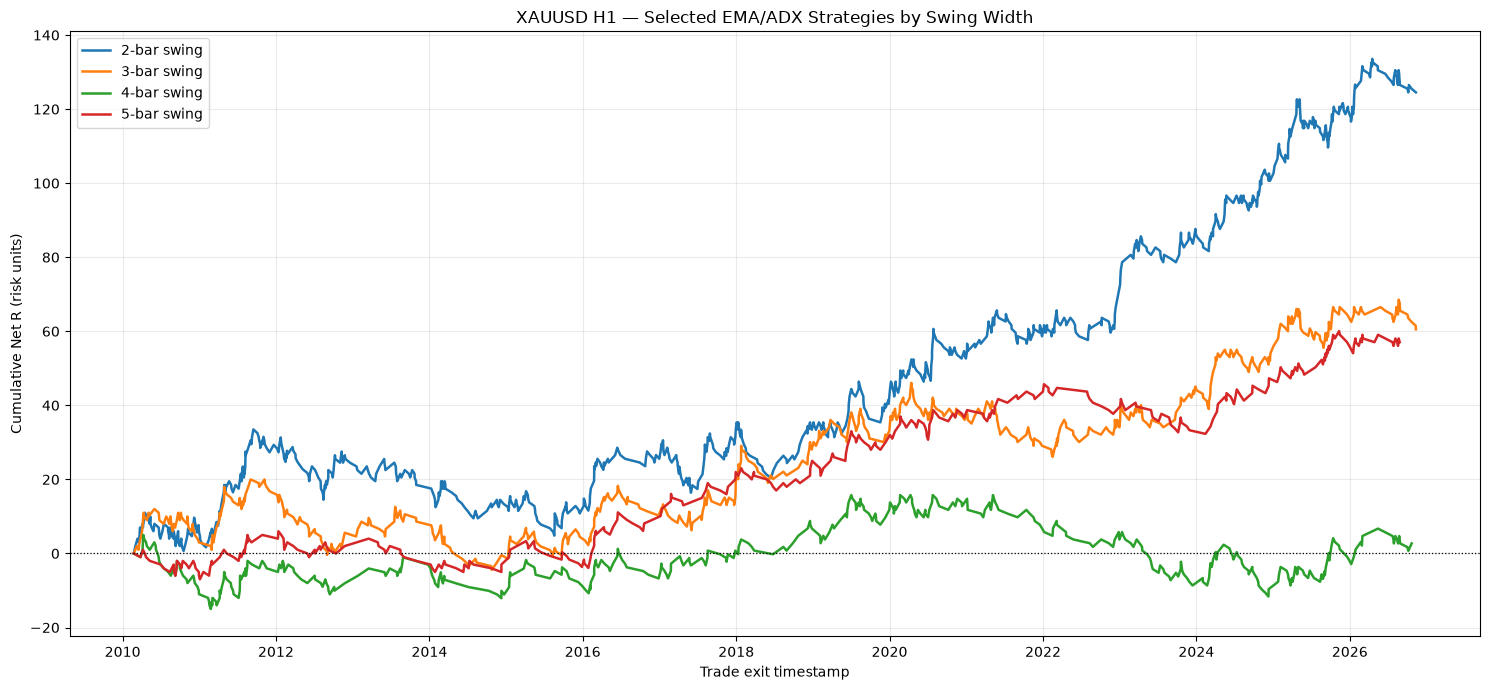

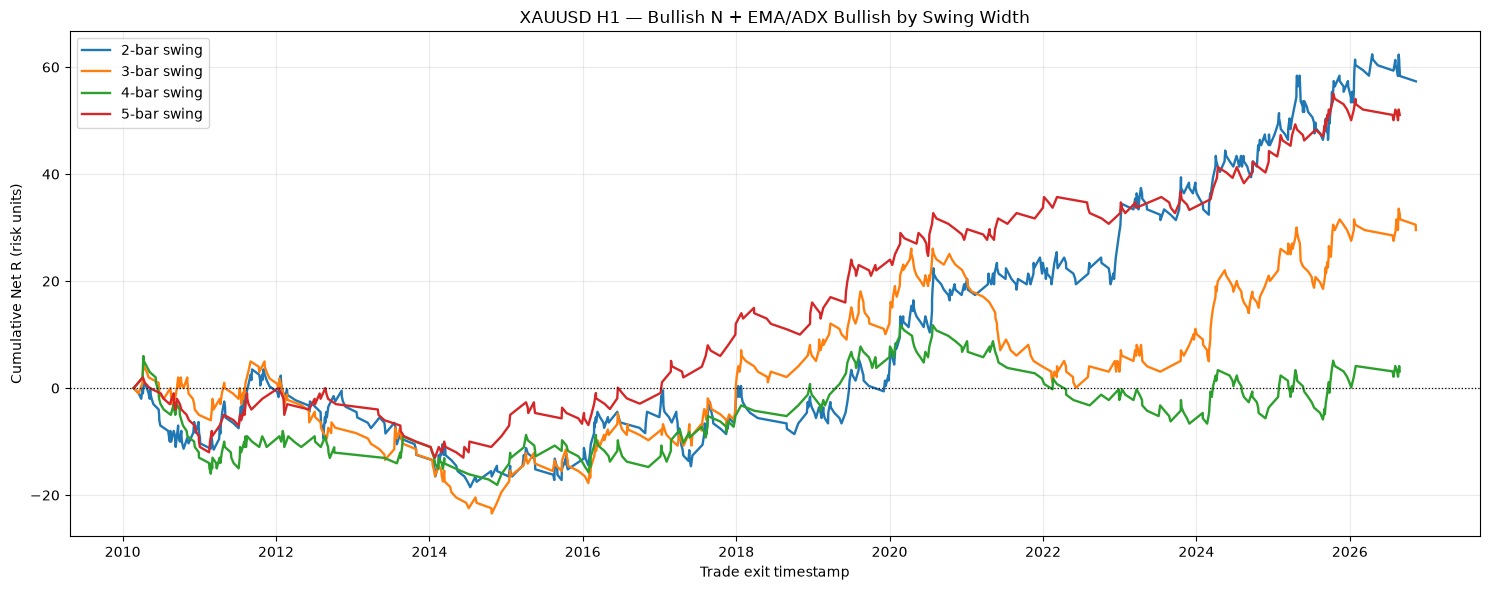

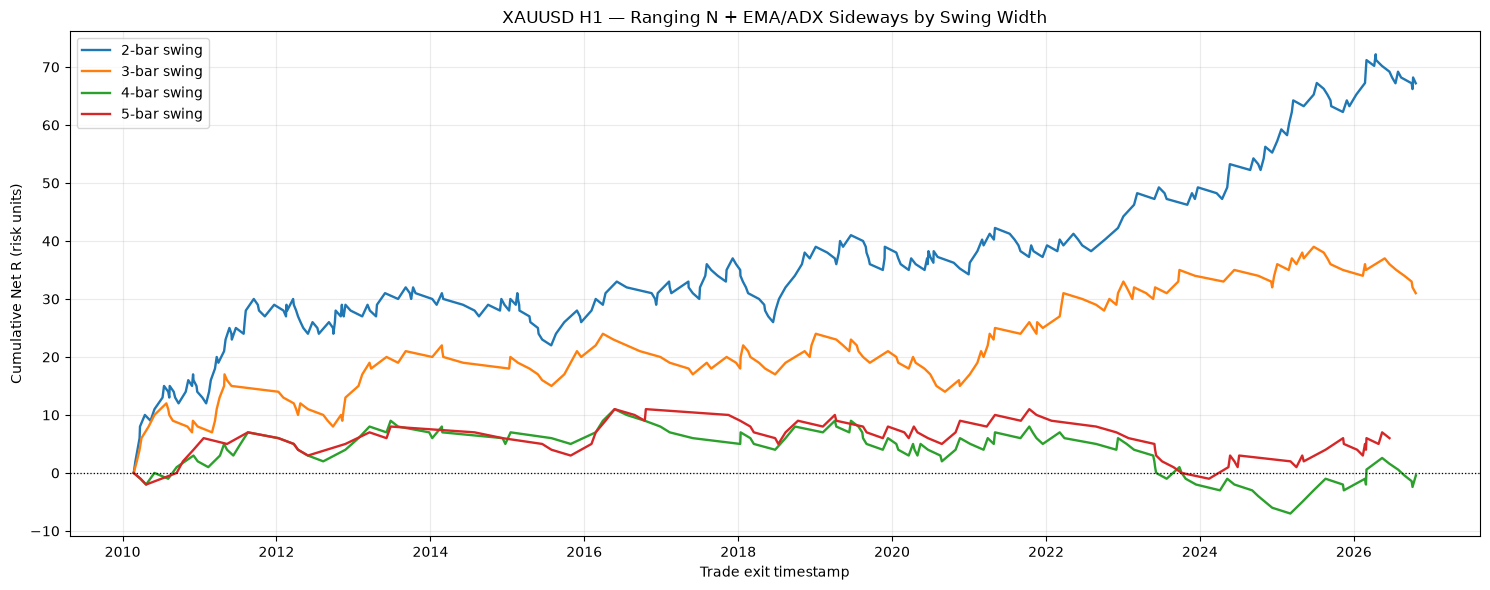

Saved charts:
 - /Users/febrianamisdianti/Documents/XAUUSD_regime_analysis_on_n_pattern/assets/h1_swing_width_selected_cumulative_R.png
 - /Users/febrianamisdianti/Documents/XAUUSD_regime_analysis_on_n_pattern/assets/h1_swing_width_bullish_component.png
 - /Users/febrianamisdianti/Documents/XAUUSD_regime_analysis_on_n_pattern/assets/h1_swing_width_ranging_component.png


In [8]:
# Combined selected strategy equity curves by swing width.
plt.figure(figsize=(15, 7))
curve_data = {}
for swing_bars in SWING_WIDTHS:
    curve = cumulative_r_curve(selected_frames[swing_bars], data.index.min())
    curve_data[f"{swing_bars}-bar swing"] = curve
    if not curve.empty:
        plt.plot(curve.index, curve.values, linewidth=1.8, label=f"{swing_bars}-bar swing")
plt.axhline(0, color="black", linewidth=0.9, linestyle=":")
plt.title("XAUUSD H1 — Selected EMA/ADX Strategies by Swing Width")
plt.xlabel("Trade exit timestamp")
plt.ylabel("Cumulative Net R (risk units)")
plt.grid(True, alpha=0.25)
plt.legend()
plt.tight_layout()
combined_curve_path = ASSET_DIR / "h1_swing_width_selected_cumulative_R.png"
plt.savefig(combined_curve_path, dpi=160, bbox_inches="tight")
plt.show()

# Component-level cumulative curves.
for setup_name, regime_name, label, filename in [
    ("bullish", "Bullish", "Bullish N + EMA/ADX Bullish", "h1_swing_width_bullish_component.png"),
    ("ranging", "Sideways", "Ranging N + EMA/ADX Sideways", "h1_swing_width_ranging_component.png"),
]:
    plt.figure(figsize=(15, 6))
    for swing_bars in SWING_WIDTHS:
        frame = selected_frames[swing_bars]
        component = frame[frame["setup"].eq(setup_name)] if not frame.empty else frame
        curve = cumulative_r_curve(component, data.index.min())
        if not curve.empty:
            plt.plot(curve.index, curve.values, linewidth=1.7, label=f"{swing_bars}-bar swing")
    plt.axhline(0, color="black", linewidth=0.9, linestyle=":")
    plt.title(f"XAUUSD H1 — {label} by Swing Width")
    plt.xlabel("Trade exit timestamp")
    plt.ylabel("Cumulative Net R (risk units)")
    plt.grid(True, alpha=0.25)
    plt.legend()
    plt.tight_layout()
    plt.savefig(ASSET_DIR / filename, dpi=160, bbox_inches="tight")
    plt.show()

print("Saved charts:")
for p in [combined_curve_path, ASSET_DIR / "h1_swing_width_bullish_component.png", ASSET_DIR / "h1_swing_width_ranging_component.png"]:
    print(" -", p)

## 7. Inspect component contribution and drawdown

The combined result can hide the fact that one component is profitable while the other is losing. Compare Bullish N and Ranging N separately before interpreting a combined result. Maximum drawdown is calculated on the cumulative trade-level R curve, starting from zero.

In [9]:
component_pivot = experiment_summary[
    experiment_summary["Selection"].isin([
        "Bullish N + EMA/ADX Bullish", "Ranging N + EMA/ADX Sideways"
    ])
].pivot(index="Swing bars each side", columns="Selection", values="Net R")
display(component_pivot.round(3))

combined_summary = experiment_summary[
    experiment_summary["Selection"].eq("Combined selected strategies")
].sort_values("Swing bars each side").reset_index(drop=True)
display(combined_summary[[
    "Swing bars each side", "Pivot window bars", "Trades", "Win rate %",
    "Net R", "Profit factor", "Avg R", "Max drawdown R", "Ambiguous signals"
]].round(3))

Selection,Bullish N + EMA/ADX Bullish,Ranging N + EMA/ADX Sideways
Swing bars each side,,
2,57.332,67.191
3,29.536,31.000
4,3.127,-0.418
5,51.062,6.000


,Swing bars each side,Pivot window bars,Trades,Win rate %,Net R,Profit factor,Avg R,Max drawdown R,Ambiguous signals
0,2,5,872,38.188,124.523,1.229,0.143,-28.684,0
1,3,7,614,36.808,60.536,1.155,0.099,-24.431,0
2,4,9,450,33.556,2.709,1.009,0.006,-27.413,0
3,5,11,344,38.953,57.062,1.270,0.166,-13.416,0


## 8. Export results

The notebook writes reproducible CSV outputs and PNG charts into the project `outputs/` and `assets/` folders.

In [10]:
setup_counts.to_csv(OUTPUT_DIR / "XAUUSD_H1_swing_width_setup_counts.csv", index=False)
experiment_summary.to_csv(OUTPUT_DIR / "XAUUSD_H1_swing_width_regime_filtered_performance.csv", index=False)
if not all_trades_by_width.empty:
    all_trades_by_width.to_csv(OUTPUT_DIR / "XAUUSD_H1_all_trades_by_swing_width.csv", index=False)
if not selected_trades_by_width.empty:
    selected_trades_by_width.to_csv(OUTPUT_DIR / "XAUUSD_H1_selected_trades_by_swing_width.csv", index=False)

curve_frames = []
for swing_bars, frame in selected_frames.items():
    curve = cumulative_r_curve(frame, data.index.min())
    if not curve.empty:
        tmp = curve.rename("Cumulative Net R").rename_axis("exit_date").reset_index()
        tmp["Swing bars each side"] = swing_bars
        curve_frames.append(tmp)
if curve_frames:
    pd.concat(curve_frames, ignore_index=True).to_csv(
        OUTPUT_DIR / "XAUUSD_H1_swing_width_cumulative_R.csv", index=False
    )

print("Exported experiment files to:")
for name in [
    "XAUUSD_H1_swing_width_setup_counts.csv",
    "XAUUSD_H1_swing_width_regime_filtered_performance.csv",
    "XAUUSD_H1_all_trades_by_swing_width.csv",
    "XAUUSD_H1_selected_trades_by_swing_width.csv",
    "XAUUSD_H1_swing_width_cumulative_R.csv",
]:
    print(" -", OUTPUT_DIR / name)

Exported experiment files to:
 - /Users/febrianamisdianti/Documents/XAUUSD_regime_analysis_on_n_pattern/outputs/XAUUSD_H1_swing_width_setup_counts.csv
 - /Users/febrianamisdianti/Documents/XAUUSD_regime_analysis_on_n_pattern/outputs/XAUUSD_H1_swing_width_regime_filtered_performance.csv
 - /Users/febrianamisdianti/Documents/XAUUSD_regime_analysis_on_n_pattern/outputs/XAUUSD_H1_all_trades_by_swing_width.csv
 - /Users/febrianamisdianti/Documents/XAUUSD_regime_analysis_on_n_pattern/outputs/XAUUSD_H1_selected_trades_by_swing_width.csv
 - /Users/febrianamisdianti/Documents/XAUUSD_regime_analysis_on_n_pattern/outputs/XAUUSD_H1_swing_width_cumulative_R.csv


## 9. Research interpretation and limitations

1. **Only swing width changes.** ATR, entry/stop buffers, risk-reward, range tolerance, pending-order expiry, EMA/ADX settings, and backtest execution assumptions remain fixed.
2. **Regime uses signal-time information.** Every trade is assigned the EMA/ADX regime at its N-pattern confirmation timestamp. The signal must be known before the pending order becomes active on the next H1 candle.
3. **Confirmation delay differs by design.** A 2-bar swing is confirmed after two right-side candles; a 5-bar swing is confirmed after five. This changes both signal timing and price structure, not just pivot sensitivity.
4. **Full-sample selection risk.** The four widths are compared on the full historical dataset. Choosing the best width after inspecting these results creates multiple-testing / selection bias. Freeze a candidate width and test it on a new unseen period or by walk-forward validation.
5. **Ranging N is a custom operational definition.** It uses two similar highs and two similar lows within 0.50 ATR. It is not verified as an exact proprietary Traders Family rule.
6. **Trade streams are not a shared-capital portfolio.** Bullish and Ranging components can overlap in time. The combined Net R does not enforce cross-strategy position limits, capital allocation, margin, or portfolio risk.
7. **Costs are excluded.** Spread, commission, swap, and slippage are not modeled. These can materially affect H1 results.
8. **Open trades at sample end.** `OPEN_AT_END` outcomes are marked to the final close and are not realized closed trades.
9. **Historical exploratory results only.** No result in this notebook should be interpreted as a validated trading system or a claim of live profitability.

### Research question

**How sensitive is the EMA/ADX-filtered N-Method performance to the swing-pivot confirmation width, and does any apparent improvement persist on genuinely unseen H1 data?**

The next step after reviewing these exploratory results is not to keep optimizing the same historical period. It is to pre-select a swing width, freeze all rules, and evaluate it using a new chronological holdout or repeated walk-forward testing with realistic costs.